# Pump Availability Forecast

**Goal:** predict the hours (0–24) the pump will be available on each day from **16 Nov 2026** for the next **30 days**, using `pump_aval.csv` (1 Jan – 15 Nov 2026).

**Steps**
1. Load and clean the data
2. Explore it (what does availability actually look like?)
3. Choose a modelling approach
4. Build baselines, a Markov-chain model and a machine-learning model
5. Backtest them fairly (forecast 30 days ahead, many times, on past data)
6. Forecast 16 Nov onwards with the best model and save it

## Step 1 – Load and clean the data
The dates are written **day/month/year** (e.g. `15/03/2026`), so we must tell pandas that explicitly, otherwise it mixes up days and months.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv("../pump_aval.csv", encoding="utf-8-sig")
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
s = df.set_index("Date")["Availability"].astype(float).sort_index()

# Sanity checks: no gaps, no duplicates, values inside 0-24
full_range = pd.date_range(s.index.min(), s.index.max(), freq="D")
print("Rows:", len(s), "| expected days:", len(full_range))
print("Missing days:", len(full_range.difference(s.index)))
print("Duplicate dates:", s.index.duplicated().sum())
print("Min/Max hours:", s.min(), s.max())
print("From", s.index.min().date(), "to", s.index.max().date())

Rows: 319 | expected days: 319
Missing days: 0
Duplicate dates: 0
Min/Max hours: 0.0 24.0
From 2026-01-01 to 2026-11-15


## Step 2 – Explore the data

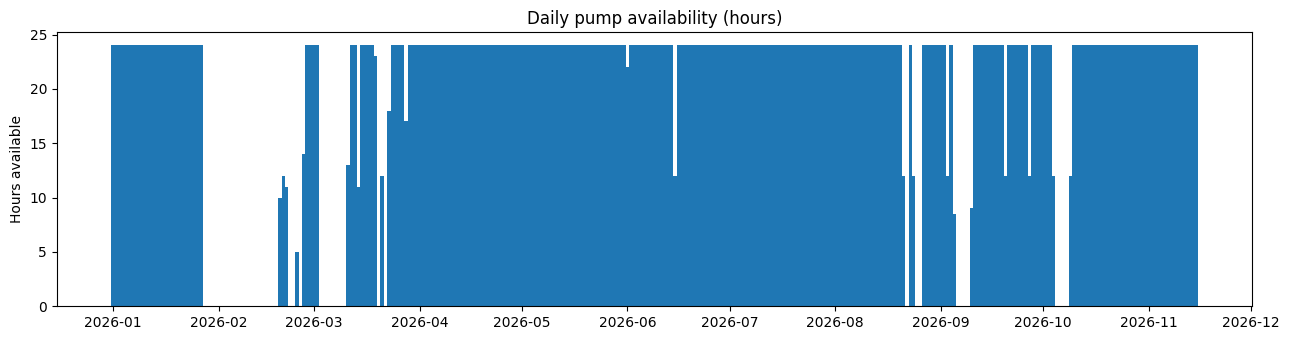

Share of days fully available (24h): 78.7 %
Share of days fully down (0h):       14.4 %
Share of days partly available:      6.9 %
Average availability: 19.77 hours/day

            avg hours
Date                 
2026-01-01       20.9
2026-02-01        3.6
2026-03-01       14.6
2026-04-01       24.0
2026-05-01       24.0
2026-06-01       23.5
2026-07-01       24.0
2026-08-01       20.9
2026-09-01       18.6
2026-10-01       20.1
2026-11-01       24.0


In [3]:
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(s.index, s.values, width=1.0)
ax.set_title("Daily pump availability (hours)")
ax.set_ylabel("Hours available")
plt.tight_layout(); plt.show()

print("Share of days fully available (24h):", round((s == 24).mean() * 100, 1), "%")
print("Share of days fully down (0h):      ", round((s == 0).mean() * 100, 1), "%")
print("Share of days partly available:     ", round(((s > 0) & (s < 24)).mean() * 100, 1), "%")
print("Average availability:", round(s.mean(), 2), "hours/day")

# Monthly average
print()
print(s.resample("MS").mean().round(1).rename("avg hours").to_frame())

### What the plot tells us
- The pump is **24 h on most days**, with occasional **outage periods** (runs of 0 h) and some partial days.
- Outages come in **spells** — if the pump was down yesterday it is much more likely to be down today. That "memory" is what a model can use.
- Outage *start dates* look essentially random, so far-ahead forecasts will naturally drift towards the long-run average. This is expected, not a model flaw.

In [4]:
# Length of each consecutive outage (days with 0 hours)
is_down = (s == 0).astype(int)
run_id = (is_down != is_down.shift()).cumsum()
runs = is_down.groupby(run_id).agg(["first", "size"])
outages = runs[runs["first"] == 1]["size"]
print("Number of outage spells:", len(outages))
print("Spell lengths (days):", outages.tolist())

Number of outage spells: 10
Spell lengths (days): [22, 2, 1, 8, 1, 1, 1, 2, 4, 4]


## Step 3 – Modelling approach
With only ~320 days and a handful of outage events, a very complex model would overfit. We compare three simple ideas:

| Model | Idea |
|---|---|
| **Baselines** | "Same as the last day", "average of last 30 days", "overall average" |
| **Markov chain** | Classify each day as *Down (0h)*, *Partial*, or *Full (24h)*. Learn the chance of moving between states, then project forward from today's state. |
| **Random Forest** | Predict tomorrow's hours from lags and rolling averages, then feed predictions back in to go day by day (*recursive forecasting*). |

All are judged on a **rolling-origin backtest**: pretend it is some past date, forecast the next 30 days, compare with what really happened, repeat.

## Step 4a – Baselines and the Markov-chain model

In [5]:
HORIZON = 30

def forecast_last_value(hist, h=HORIZON):
    return np.repeat(hist.iloc[-1], h)

def forecast_mean30(hist, h=HORIZON):
    return np.repeat(hist.iloc[-30:].mean(), h)

def forecast_overall_mean(hist, h=HORIZON):
    return np.repeat(hist.mean(), h)

# ---- Markov chain ----
def to_state(x):
    return np.where(x == 0, 0, np.where(x == 24, 2, 1))   # 0=down, 1=partial, 2=full

def forecast_markov(hist, h=HORIZON):
    states = to_state(hist.values)
    # Count transitions, with +1 smoothing so no probability is exactly 0
    counts = np.ones((3, 3))
    for a, b in zip(states[:-1], states[1:]):
        counts[a, b] += 1
    P = counts / counts.sum(axis=1, keepdims=True)

    # Average hours in each state (down=0, full=24, partial = observed mean)
    partial = hist[(hist > 0) & (hist < 24)]
    hours_in_state = np.array([0.0, partial.mean() if len(partial) else 12.0, 24.0])

    dist = np.zeros(3); dist[states[-1]] = 1.0      # we know today's state
    out = []
    for _ in range(h):
        dist = dist @ P                              # step one day forward
        out.append(dist @ hours_in_state)            # expected hours
    return np.array(out)

# Show the learned transition matrix
st = to_state(s.values)
cnt = np.ones((3, 3))
for a, b in zip(st[:-1], st[1:]): cnt[a, b] += 1
P = cnt / cnt.sum(axis=1, keepdims=True)
print(pd.DataFrame(P, index=["from Down", "from Partial", "from Full"],
                   columns=["to Down", "to Partial", "to Full"]).round(3))

              to Down  to Partial  to Full
from Down       0.755       0.184    0.061
from Partial    0.360       0.120    0.520
from Full       0.012       0.051    0.937


Read the matrix row by row: e.g. the **"from Full"** row shows how likely the pump is to stay at 24 h tomorrow, and the **"from Down"** row shows how sticky outages are.

## Step 4b – Machine-learning model (Random Forest, recursive)
We turn the series into a table: each row's inputs are *past* values only (no peeking at the future).

In [6]:
def make_features(series):
    f = pd.DataFrame(index=series.index)
    f["lag1"]  = series.shift(1)
    f["lag2"]  = series.shift(2)
    f["lag3"]  = series.shift(3)
    f["lag7"]  = series.shift(7)
    f["mean3"]  = series.shift(1).rolling(3).mean()
    f["mean7"]  = series.shift(1).rolling(7).mean()
    f["mean14"] = series.shift(1).rolling(14).mean()
    f["mean30"] = series.shift(1).rolling(30).mean()
    f["down_last7"] = (series.shift(1).rolling(7).apply(lambda x: (x == 0).sum(), raw=True))
    f["dow"] = series.index.dayofweek
    return f

def forecast_rf(hist, h=HORIZON, seed=42):
    X = make_features(hist).dropna()
    y = hist.loc[X.index]
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=seed, n_jobs=-1)
    model.fit(X, y)

    work = hist.copy()
    preds = []
    for _ in range(h):
        next_day = work.index[-1] + pd.Timedelta(days=1)
        work.loc[next_day] = np.nan                       # placeholder for the day to predict
        x_next = make_features(work).iloc[[-1]]
        p = float(np.clip(model.predict(x_next)[0], 0, 24))
        work.loc[next_day] = p                            # feed prediction back in
        preds.append(p)
    return np.array(preds)

## Step 5 – Backtest (how good is each model really?)
We move a "pretend today" through the past, forecast the next 30 days from only the data before it, and compare with reality. We report **MAE** (average error in hours) and **RMSE** (punishes big misses, e.g. predicting 24 h on a 0 h day).

In [7]:
models = {
    "Last value":    forecast_last_value,
    "Mean last 30d": forecast_mean30,
    "Overall mean":  forecast_overall_mean,
    "Markov chain":  forecast_markov,
    "Random Forest": forecast_rf,
}

origins = range(90, len(s) - HORIZON + 1, 10)   # need ~90 days of history to start
errs = {name: [] for name in models}

for o in origins:
    hist, actual = s.iloc[:o], s.iloc[o:o + HORIZON].values
    for name, fn in models.items():
        errs[name].append(actual - fn(hist))

rows = []
for name, e in errs.items():
    e = np.concatenate(e)
    rows.append({"Model": name, "MAE (hours)": np.abs(e).mean(), "RMSE (hours)": np.sqrt((e ** 2).mean())})
results = pd.DataFrame(rows).set_index("Model").round(2).sort_values("RMSE (hours)")
print(f"Backtest: {len(list(origins))} forecast origins x {HORIZON} days")
print(results)
results

Backtest: 20 forecast origins x 30 days
               MAE (hours)  RMSE (hours)
Model                                   
Mean last 30d         3.49          6.46
Random Forest         3.75          7.25
Markov chain          6.61          7.58
Overall mean          7.02          7.86
Last value            4.03          9.12


,MAE (hours),RMSE (hours)
Model,,
Mean last 30d,3.49,6.46
Random Forest,3.75,7.25
Markov chain,6.61,7.58
Overall mean,7.02,7.86
Last value,4.03,9.12


**How to read this:** the lowest numbers win. Note that MAE tends to favour "always say 24", because 24 is the most common value, while RMSE favours forecasts close to the *expected* value. For planning (e.g. expected pumping hours) the RMSE ranking is usually the more useful one, so we choose the final model by RMSE.

## Step 6 – Forecast 16 Nov 2026 onwards

In [8]:
best = results.index[0]
print("Best model by RMSE:", best)

future_dates = pd.date_range(s.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq="D")
forecast = pd.DataFrame({name: fn(s) for name, fn in models.items()}, index=future_dates)
forecast["Forecast (best model)"] = forecast[best]
forecast = forecast.round(1)
forecast.index.name = "Date"

forecast

Best model by RMSE: Mean last 30d


,Last value,Mean last 30d,Overall mean,Markov chain,Random Forest,Forecast (best model)
Date,,,,,,
2026-11-16,24.0,24.0,19.8,23.1,23.5,24.0
2026-11-17,24.0,24.0,19.8,22.4,24.0,24.0
2026-11-18,24.0,24.0,19.8,21.9,24.0,24.0
2026-11-19,24.0,24.0,19.8,21.4,24.0,24.0
2026-11-20,24.0,24.0,19.8,21.1,23.1,24.0
2026-11-21,24.0,24.0,19.8,20.8,22.5,24.0
2026-11-22,24.0,24.0,19.8,20.5,22.2,24.0
2026-11-23,24.0,24.0,19.8,20.3,22.0,24.0
2026-11-24,24.0,24.0,19.8,20.2,22.6,24.0


**Reading the table:** if the backtest winner is the simple *"mean of last 30 days"* and the pump has run 24 h every day recently, that forecast is a flat 24 h. It won the backtest because outages are rare and unpredictable, but it assumes **zero outage risk**. The *Markov chain* and *Random Forest* columns are the risk-aware view: they start near 24 h and slide down as the chance of an unexpected outage builds up. Use the best-model column as the "most likely" plan and the Markov column as a cautious planning figure.

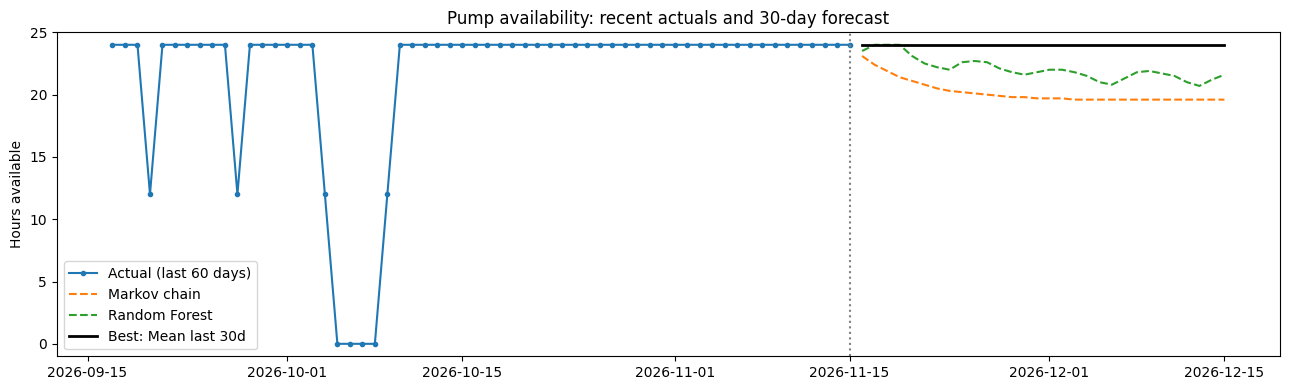

In [9]:
fig, ax = plt.subplots(figsize=(13, 4))
recent = s.iloc[-60:]
ax.plot(recent.index, recent.values, "o-", ms=3, label="Actual (last 60 days)")
for name in ["Markov chain", "Random Forest"]:
    ax.plot(forecast.index, forecast[name], "--", label=name)
ax.plot(forecast.index, forecast["Forecast (best model)"], "k-", lw=2, label=f"Best: {best}")
ax.axvline(s.index[-1], color="grey", ls=":")
ax.set_ylim(-1, 25); ax.set_ylabel("Hours available")
ax.set_title("Pump availability: recent actuals and 30-day forecast")
ax.legend(); plt.tight_layout(); plt.show()

In [10]:
out = forecast[["Forecast (best model)"]].rename(columns={"Forecast (best model)": "Predicted_Availability_Hours"})
out.index = out.index.strftime("%d/%m/%Y")
out.to_csv("pump_availability_forecast.csv")
print("Saved pump_availability_forecast.csv")
out.head()

Saved pump_availability_forecast.csv


,Predicted_Availability_Hours
Date,
16/11/2026,24.0
17/11/2026,24.0
18/11/2026,24.0
19/11/2026,24.0
20/11/2026,24.0


## Important notes & how to improve it
- **Outages can't be predicted by date.** Forecasts are *expected hours* — e.g. 22.5 h means "likely running, with some risk of an outage", not that the pump will literally run 22.5 h. Expect them to fade from today's state towards the long-run average as the horizon grows.
- **Few outage events** (see Step 2) means any model is uncertain. More history will help a lot.
- **Add real drivers if you have them:** maintenance schedules, power/fuel supply, rainfall, run-hours since last service, breakdown logs. These usually beat anything learned from the availability history alone.
- **Re-train regularly:** re-run the notebook as new days arrive; every step is automatic.
- If planned maintenance is known in advance, overwrite those days with 0 after forecasting.